# 過度擬合圖解：ML 慢慢學 EP04 的程式

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ntanh-ml/ml-manmanxue/blob/main/v05-overfitting/notebook.ipynb)

這本 notebook 產生影片裡焚化爐範例的**每一張資料圖和每一個數字**。所有資料都是**模擬資料，非實廠數據**，不代表任何一座真實焚化廠。
This notebook generates every chart and number of the incinerator example in EP04 of the YouTube channel ML 慢慢學 (https://www.youtube.com/@ml-step-by-step). All data are **simulated** and do not describe any real plant.

問題（接續 EP03）：**模型在舊資料上很準，換成新資料，還準嗎？**

| 段落 | 對應影片 |
|---|---|
| 1. 沿用 EP03 的模擬資料，切成訓練集和驗證集 | 第 2、6 段 |
| 2. 多項式特徵：讓模型更有彈性 | 第 2 段 |
| 3. 次數越高，訓練誤差越小；驗證誤差呢？ | 第 3、4 段 |
| 4. 過度擬合的模型，權重大得誇張 | 第 7 段 |
| 5. L2 正則化，用驗證集挑 λ | 第 7 段 |
| 6. 鎖定設定（之後不再改） | 第 6 段 |
| 7. 測試集：全新的 4 天，只評估這一次 | 第 8 段 |
| 8. 為什麼時間序列不能打散再分 | 第 6 段 |
| 9. 匯出資料給影片使用 | — |

**流程紀律**：第 1–6 段只看訓練集和驗證集。測試集（用另一個亂數種子模擬的 4 天）在第 6 段鎖定設定之後才產生，並且只評估一次。

參考：Lazer, D., Kennedy, R., King, G., & Vespignani, A. (2014). The parable of Google Flu: Traps in big data analysis. *Science*, 343(6176), 1203–1205；EP03 notebook（同一個 repo 的 `v04-multiple-linear-regression`）；《廢棄物焚化爐戴奧辛管制及排放標準》第 7 條。

In [1]:
import itertools
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

PAPER, INK, RED, BLUE, AMBER, TEAL = "#F6F1E7", "#3B2F2A", "#D8573C", "#4FA3D1", "#D79A2B", "#2A9D8F"
LABEL = "模擬資料，非實廠數據"

# Chinese font for the plots. Uses LXGW WenKai TC (OFL) if present; otherwise Noto Sans CJK.
# On Google Colab the Noto CJK font is installed automatically so the Chinese labels display correctly.
import subprocess, sys
FONT = Path("../../tools/fonts/LXGWWenKaiTC-Medium.ttf")
CJK = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if not FONT.exists() and not CJK.exists() and "google.colab" in sys.modules:
    print("正在安裝中文字型（約 30 秒）…")
    if subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"]).returncode != 0:
        subprocess.run(["apt-get", "-qq", "update"])
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"])
for f in (FONT, CJK):
    if f.exists():
        font_manager.fontManager.addfont(str(f))
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(f)).get_name()
        break
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.unicode_minus": False})

def tag(ax):
    ax.text(0.99, 0.97, LABEL, transform=ax.transAxes, ha="right", va="top", fontsize=8, color=RED)

def mae(a, b): return float(np.abs(a - b).mean())

## 1. 沿用 EP03 的模擬資料，切成訓練集和驗證集
模擬方式和 EP03 完全相同（同一個亂數種子 2026、14 天、每分鐘一筆、4 個感測器）。答案欄一樣是**接下來 60 分鐘的平均蒸汽流量**。

這一集**故意只給模型少量訓練資料**：前 8 天裡每小時取一筆。資料少，過度擬合才看得清楚。

| 資料 | 用途 |
|---|---|
| 第 1–8 天，每小時一筆 | 訓練集：算權重 |
| 第 9–14 天，每分鐘一筆 | 驗證集：挑次數、挑 λ |
| 另外模擬的 4 天（第 7 段才產生） | 測試集：最後只評估一次 |

In [2]:
def lag(x, tau):
    # 一階延遲 (first-order lag)
    y = np.empty_like(x); y[0] = x[0]
    for i in range(1, len(x)):
        y[i] = y[i - 1] + (x[i] - y[i - 1]) / tau
    return y

def simulate(seed, days):
    # 和 EP03 notebook 第 1 段完全相同的模擬（亂數呼叫順序也相同）
    rng = np.random.default_rng(seed)
    N = days * 1440
    MU, SD = 2050.0, 150.0
    PHI = np.exp(-1 / 120)
    lhv = np.empty(N); lhv[0] = MU
    noise = rng.normal(0, SD * np.sqrt(1 - PHI ** 2), N)
    for i in range(1, N):
        lhv[i] = MU + PHI * (lhv[i - 1] - MU) + noise[i]
    lhv = np.clip(lhv, 1500, 2500)
    F_set = np.empty(N); i, level = 0, 12.5
    while i < N:
        length = int(rng.integers(120, 360))
        level = float(np.clip(level + rng.normal(0, 0.7), 10.5, 14.5))
        F_set[i:i + length] = level; i += length
    feed = lag(F_set, 15) + rng.normal(0, 0.15, N)
    trim = np.empty(N); trim[0] = 0.0
    PT = np.exp(-1 / 180)
    e_trim = rng.normal(0, 0.06 * np.sqrt(1 - PT ** 2), N)
    for i in range(1, N):
        trim[i] = PT * trim[i - 1] + e_trim[i]
    air = lag(3000 * F_set * (1 + trim), 5) + rng.normal(0, 400, N)
    Q0 = 12.5 * MU
    q = feed * lhv / Q0
    air_rel = air / (3000 * 12.5)
    temp = 960 + 200 * (lag(q, 4) - 1) - 80 * (air_rel - 1) + rng.normal(0, 5, N)
    o2 = 8.0 - 3.0 * (lag(q, 3) - 1) + 4.5 * (air_rel - 1) + rng.normal(0, 0.2, N)
    steam = lag(feed * lhv * 0.8 / 670 - 4 * (air_rel - 1), 10) + rng.normal(0, 0.3, N)
    raw = np.c_[feed, air, temp, o2]
    # 法規範圍檢查：二次空氣後 ≥ 850°C、排氣含氧量 ≥ 6%
    assert temp.min() > 850 and 6 <= o2.min() and o2.max() < 10 and air.min() > 10000
    return raw, steam

H = 60
def make_xy(raw, steam):
    cs = np.cumsum(np.r_[0.0, steam])
    rows = np.arange(len(steam) - H)
    y = (cs[rows + 1 + H] - cs[rows + 1]) / H      # steam[t+1 .. t+60] 的平均
    return raw[rows], y

NAMES = ["進料量", "一次空氣流量", "爐溫", "含氧量"]
raw, steam = simulate(2026, 14)
X, y = make_xy(raw, steam)

# 確認資料和 EP03 一樣：比對 EP03 匯出的感測器平均（前 10 天訓練列）
ep03 = Path("../v04-multiple-linear-regression/data/v04.json")
if ep03.exists():
    ref = json.loads(ep03.read_text(encoding="utf-8"))["sensors"]["mean"]
    assert np.allclose(X[:10 * 1440 - H].mean(0), ref, atol=1e-3), "資料和 EP03 不一致"
    print("資料和 EP03 相同（感測器平均一致）")

TRAIN_DAYS, VAL_DAYS, STEP = 8, 6, 60
TR = np.arange(0, TRAIN_DAYS * 1440 - H, STEP)                  # 訓練列：每小時一筆；最後 60 分鐘不用（答案會用到驗證期）
VA = np.arange(TRAIN_DAYS * 1440, 14 * 1440 - H)                # 驗證列：第 9–14 天每分鐘
assert TR.max() + H < VA.min()
print(f"訓練集 {len(TR)} 筆（{TRAIN_DAYS} 天、每 {STEP} 分鐘一筆）；驗證集 {len(VA):,} 筆（{VAL_DAYS} 天、每分鐘一筆）")
print(f"訓練集的蒸汽流量答案：平均 {y[TR].mean():.1f}、最小 {y[TR].min():.1f}、最大 {y[TR].max():.1f} t/h")

資料和 EP03 相同（感測器平均一致）
訓練集 191 筆（8 天、每 60 分鐘一筆）；驗證集 8,580 筆（6 天、每分鐘一筆）
訓練集的蒸汽流量答案：平均 31.3、最小 25.3、最大 39.8 t/h


## 2. 多項式特徵：讓模型更有彈性
EP03 的式子只有一次項：$\hat y = w_1x_1 + w_2x_2 + w_3x_3 + w_4x_4 + b$。
把感測器的平方、三次方、彼此相乘也放進去，就是**多項式特徵**。4 個感測器、最高 $d$ 次，一共有 $\binom{4+d}{d}$ 個係數（包含截距 $b$）。

做法（順序很重要）：
1. 4 個感測器先標準化（平均和標準差只用訓練集算）。
2. 產生各次方和交叉相乘的欄位。
3. **每個多項式欄位再標準化一次**（同樣只用訓練集），這樣第 5 段的 L2 罰金對每一欄才公平。
4. 截距 $b$ 不罰。

In [3]:
def expand(Z, deg):
    cols = []
    for d in range(1, deg + 1):
        for idx in itertools.combinations_with_replacement(range(Z.shape[1]), d):
            cols.append(np.prod(Z[:, idx], axis=1))
    return np.c_[tuple(cols)] if cols else np.empty((len(Z), 0))

class PolyModel:
    # 多項式迴歸；lam = 0 是一般最小平方法，lam > 0 是 L2 正則化（ridge）。損失 = MSE + lam × Σ w_j²（不含 b）
    def __init__(self, deg, lam=0.0):
        self.deg, self.lam = deg, lam
    def _design(self, Xr):
        P = expand((Xr - self.mu) / self.sd, self.deg)
        return (P - self.pm) / self.ps if P.shape[1] else P
    def fit(self, Xr, yr):
        self.mu, self.sd = Xr.mean(0), Xr.std(0)
        P = expand((Xr - self.mu) / self.sd, self.deg)
        self.pm = P.mean(0) if P.shape[1] else np.zeros(0)
        self.ps = P.std(0) if P.shape[1] else np.ones(0)
        A = np.c_[np.ones(len(Xr)), (P - self.pm) / self.ps] if P.shape[1] else np.ones((len(Xr), 1))
        if self.lam == 0:
            self.coef, *_ = np.linalg.lstsq(A, yr, rcond=None)      # 係數比資料多時，取長度最小的解
        else:
            R = np.eye(A.shape[1]); R[0, 0] = 0
            self.coef = np.linalg.solve(A.T @ A + self.lam * len(yr) * R, A.T @ yr)
        return self
    def predict(self, Xr):
        return np.c_[np.ones(len(Xr)), self._design(Xr)] @ self.coef
    @property
    def n_coef(self): return len(self.coef)
    @property
    def max_abs_w(self): return float(np.abs(self.coef[1:]).max()) if len(self.coef) > 1 else 0.0

for d in range(0, 7):
    print(f"{d} 次：{PolyModel(d).fit(X[TR], y[TR]).n_coef:3d} 個係數（包含截距）")

0 次：  1 個係數（包含截距）
1 次：  5 個係數（包含截距）
2 次： 15 個係數（包含截距）
3 次： 35 個係數（包含截距）
4 次： 70 個係數（包含截距）
5 次：126 個係數（包含截距）
6 次：210 個係數（包含截距）


### 一個感測器的示意：次數越高，線越會彎
只拿「進料量」一個輸入、20 筆訓練資料，分別用 1 次、3 次、9 次去配。這張圖只是幫助理解「彈性」，影片第 2 段使用。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


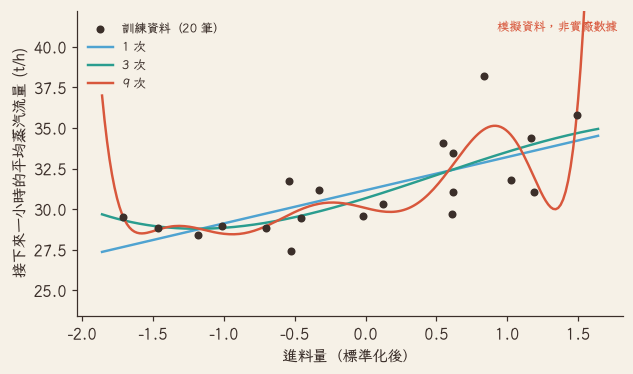

In [4]:
demo_idx = TR[::len(TR) // 20][:20]
xd = (X[demo_idx, 0] - X[TR, 0].mean()) / X[TR, 0].std()
yd = y[demo_idx]
grid = np.linspace(xd.min() - 0.15, xd.max() + 0.15, 200)
demo_curves = {}
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.scatter(xd, yd, s=18, color=INK, zorder=3, label="訓練資料（20 筆）")
for d, c in [(1, BLUE), (3, TEAL), (9, RED)]:
    p = np.polynomial.Polynomial.fit(xd, yd, d)
    demo_curves[d] = p(grid)
    ax.plot(grid, np.clip(p(grid), yd.min() - 6, yd.max() + 6), color=c, lw=1.6, label=f"{d} 次")
ax.set_ylim(yd.min() - 4, yd.max() + 4)
ax.set_xlabel("進料量（標準化後）"); ax.set_ylabel("接下來一小時的平均蒸汽流量 (t/h)"); ax.legend(frameon=False, fontsize=8); tag(ax)
plt.show()

## 3. 次數越高，訓練誤差越小；驗證誤差呢？
不加罰金（一般最小平方法），次數從 0（只猜平均）加到 6。誤差用**平均絕對誤差**（公噸／小時）。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


次數  係數個數  訓練誤差  驗證誤差  最大權重絕對值
  0        1      2.43      2.69           0
  1        5     0.867     0.855        2.09
  2       15     0.835     0.934        2.07
  3       35     0.755      1.15        6.62
  4       70      0.68      2.07          58
  5      126     0.504      6.39    1.96e+03
  6      210  4.31e-12       100    3.97e+03


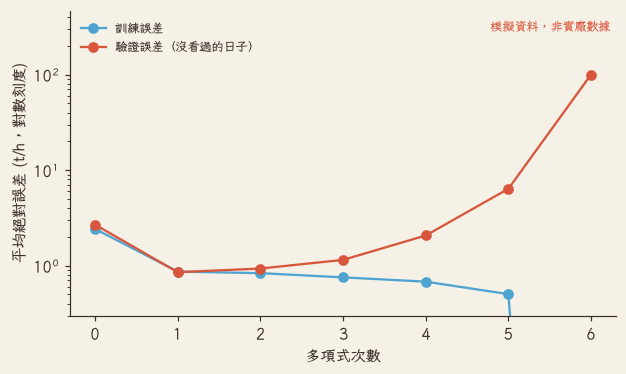

不加罰金時，驗證誤差最小的是 1 次（0.855 t/h）


In [5]:
DEGS = list(range(0, 7))
sweep = []
for d in DEGS:
    m = PolyModel(d).fit(X[TR], y[TR])
    sweep.append({"deg": d, "n_coef": m.n_coef, "mae_train": mae(y[TR], m.predict(X[TR])),
                  "mae_val": mae(y[VA], m.predict(X[VA])), "max_abs_w": m.max_abs_w})
print("次數  係數個數  訓練誤差  驗證誤差  最大權重絕對值")
for s in sweep:
    print(f"{s['deg']:>3}  {s['n_coef']:>7}  {s['mae_train']:>8.3g}  {s['mae_val']:>8.3g}  {s['max_abs_w']:>10.3g}")

# 訓練誤差不會隨次數上升（高次模型包含低次模型）
tr_err = [s["mae_train"] for s in sweep]
assert sweep[-1]["n_coef"] > len(TR) and tr_err[-1] < 1e-6, "6 次的係數比資料多，應該能把訓練資料完全配上"

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(DEGS, [s["mae_train"] for s in sweep], "o-", color=BLUE, label="訓練誤差")
ax.plot(DEGS, [s["mae_val"] for s in sweep], "o-", color=RED, label="驗證誤差（沒看過的日子）")
ax.set_yscale("log"); ax.set_ylim(0.3, None)
ax.set_xlabel("多項式次數"); ax.set_ylabel("平均絕對誤差 (t/h，對數刻度)"); ax.legend(frameon=False, fontsize=8); tag(ax)
plt.show()
best_plain = min(sweep, key=lambda s: s["mae_val"])
print(f"不加罰金時，驗證誤差最小的是 {best_plain['deg']} 次（{best_plain['mae_val']:.3f} t/h）")

## 4. 過度擬合的模型，權重大得誇張
比較 1 次和 6 次模型的權重（都已經是標準化後的欄位，可以直接比大小）。

findfont: Failed to find font weight normal for LXGW WenKai TC, now using 500.


1 次：最大權重絕對值 2.09；6 次：3973.1（1903 倍）
6 次模型在驗證集上的預測：最小 -3109、最大 3370 t/h，其中 18% 是負的；實際蒸汽流量只在 24–39 t/h 之間


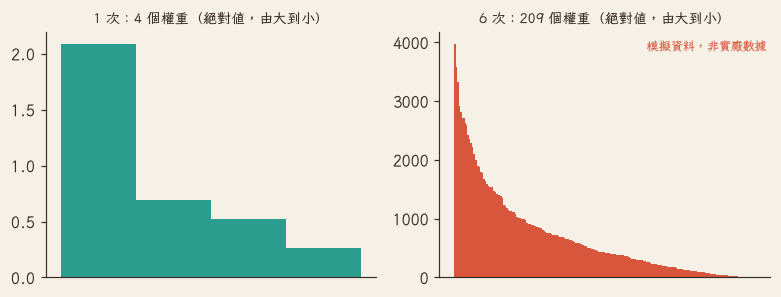

In [6]:
m1 = PolyModel(1).fit(X[TR], y[TR])
m6 = PolyModel(6).fit(X[TR], y[TR])
print(f"1 次：最大權重絕對值 {m1.max_abs_w:.2f}；6 次：{m6.max_abs_w:.1f}（{m6.max_abs_w / m1.max_abs_w:.0f} 倍）")
p6 = m6.predict(X[VA])
print(f"6 次模型在驗證集上的預測：最小 {p6.min():.0f}、最大 {p6.max():.0f} t/h，其中 {100 * (p6 < 0).mean():.0f}% 是負的；"
      f"實際蒸汽流量只在 {y[VA].min():.0f}–{y[VA].max():.0f} t/h 之間")

fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
for ax, m, name in zip(axs, [m1, m6], ["1 次", "6 次"]):
    w = np.sort(np.abs(m.coef[1:]))[::-1]
    ax.bar(range(len(w)), w, color=TEAL if m is m1 else RED, width=1.0)
    ax.set_title(f"{name}：{len(w)} 個權重（絕對值，由大到小）", fontsize=9); ax.set_xticks([])
tag(axs[1]); plt.tight_layout(); plt.show()

## 5. L2 正則化，用驗證集挑 λ
損失 $= \text{MSE} + \lambda \sum_j w_j^2$（$b$ 不罰）。$\lambda = 0$ 就是不罰；$\lambda$ 越大，權重被壓得越小。
每個次數都試同一組 λ，**只看驗證誤差**來挑。

1 次：驗證誤差最小的 λ = 0.0316（訓練 0.865、驗證 0.850、最大權重絕對值 1.99）
2 次：驗證誤差最小的 λ = 0.0316（訓練 0.842、驗證 0.897、最大權重絕對值 1.94）
3 次：驗證誤差最小的 λ = 0.1（訓練 0.855、驗證 0.907、最大權重絕對值 1.55）


4 次：驗證誤差最小的 λ = 0.1（訓練 0.822、驗證 0.944、最大權重絕對值 1.53）


5 次：驗證誤差最小的 λ = 0.316（訓練 0.906、驗證 0.971、最大權重絕對值 1.01）


6 次：驗證誤差最小的 λ = 0.316（訓練 0.883、驗證 1.065、最大權重絕對值 0.99）


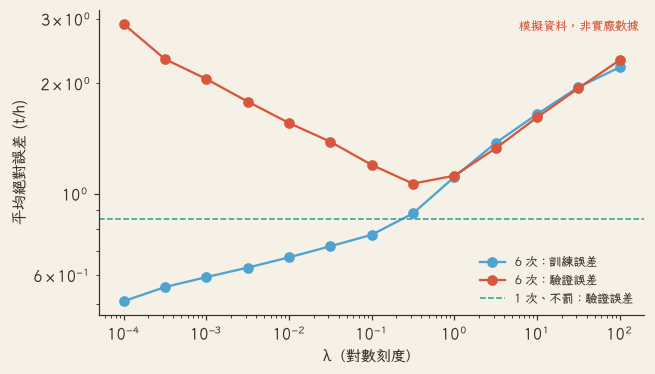

In [7]:
LAMS = [float(v) for v in 10 ** np.arange(-4, 2.01, 0.5)]        # 0.0001 … 100，共 13 個
ridge = {}
for d in range(1, 7):
    rows = []
    for lam in LAMS:
        m = PolyModel(d, lam).fit(X[TR], y[TR])
        rows.append({"lam": lam, "mae_train": mae(y[TR], m.predict(X[TR])), "mae_val": mae(y[VA], m.predict(X[VA])), "max_abs_w": m.max_abs_w})
    ridge[d] = rows
    b = min(rows, key=lambda r: r["mae_val"])
    print(f"{d} 次：驗證誤差最小的 λ = {b['lam']:.3g}（訓練 {b['mae_train']:.3f}、驗證 {b['mae_val']:.3f}、最大權重絕對值 {b['max_abs_w']:.3g}）")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(LAMS, [r["mae_train"] for r in ridge[6]], "o-", color=BLUE, label="6 次：訓練誤差")
ax.plot(LAMS, [r["mae_val"] for r in ridge[6]], "o-", color=RED, label="6 次：驗證誤差")
ax.axhline(sweep[1]["mae_val"], color=TEAL, ls="--", lw=1, label="1 次、不罰：驗證誤差")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("λ（對數刻度）"); ax.set_ylabel("平均絕對誤差 (t/h)"); ax.legend(frameon=False, fontsize=8); tag(ax)
plt.show()

## 6. 鎖定設定（之後不再改）
到這裡為止只用了訓練集和驗證集。現在把要帶去測試的模型**先寫死**：

- **A**：1 次、不罰（EP03 的直線）
- **B**：6 次、不罰（過度擬合的例子）
- **C**：6 次、L2，λ 用驗證集挑
- **D**：所有次數和 λ 裡，驗證誤差最小的那一個（「照規矩挑出來的模型」）

In [8]:
def best_ridge(d):
    return min(ridge[d], key=lambda r: r["mae_val"])

cands = [(s["mae_val"], s["deg"], 0.0) for s in sweep] + [(r["mae_val"], d, r["lam"]) for d in ridge for r in ridge[d]]
val_best = min(cands)
LOCK = {
    "A": {"deg": 1, "lam": 0.0, "name": "1 次，不罰"},
    "B": {"deg": 6, "lam": 0.0, "name": "6 次，不罰"},
    "C": {"deg": 6, "lam": best_ridge(6)["lam"], "name": "6 次＋L2"},
    "D": {"deg": int(val_best[1]), "lam": float(val_best[2]), "name": "驗證集挑出來的"},
}
for k, v in LOCK.items():
    m = PolyModel(v["deg"], v["lam"]).fit(X[TR], y[TR])
    v.update(model=m, mae_train=mae(y[TR], m.predict(X[TR])), mae_val=mae(y[VA], m.predict(X[VA])), max_abs_w=m.max_abs_w, n_coef=m.n_coef)
    print(f"{k}（{v['name']}）：{v['deg']} 次、λ = {v['lam']:.3g}｜訓練 {v['mae_train']:.3g}、驗證 {v['mae_val']:.3g}、最大權重絕對值 {v['max_abs_w']:.3g}")
gapAD = LOCK["A"]["mae_val"] - LOCK["D"]["mae_val"]
print(f"\n驗證集上 D 比 A 好 {gapAD:.3f} t/h（{100 * gapAD / LOCK['A']['mae_val']:.1f}%）")

A（1 次，不罰）：1 次、λ = 0｜訓練 0.867、驗證 0.855、最大權重絕對值 2.09
B（6 次，不罰）：6 次、λ = 0｜訓練 4.31e-12、驗證 100、最大權重絕對值 3.97e+03
C（6 次＋L2）：6 次、λ = 0.316｜訓練 0.883、驗證 1.07、最大權重絕對值 0.99
D（驗證集挑出來的）：1 次、λ = 0.0316｜訓練 0.865、驗證 0.85、最大權重絕對值 1.99

驗證集上 D 比 A 好 0.005 t/h（0.6%）


## 7. 測試集：全新的 4 天，只評估這一次
用**另一個亂數種子**（2027）和同一套模擬方式，產生 5 天資料，丟掉第 1 天（讓模擬穩定下來），留 4 天當測試集。
模型在第 6 段已經鎖定，這裡**不再調整任何東西**，四個模型各評估一次。

測試集 5,700 筆（4 天、每分鐘一筆），蒸汽流量答案 24.5–40.2 t/h



模型                      訓練    驗證    測試（全新 4 天）
A 1 次，不罰      （1 次、λ=0）   0.867   0.855   0.869
B 6 次，不罰      （6 次、λ=0）  4.31e-12     100     148
C 6 次＋L2      （6 次、λ=0.316）   0.883    1.07    1.14
D 驗證集挑出來的     （1 次、λ=0.0316）   0.865    0.85   0.864

測試誤差由小到大： D < A < C < B


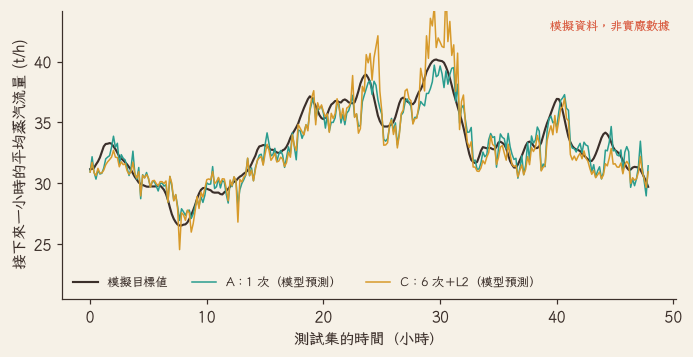

In [9]:
raw_t, steam_t = simulate(2027, 5)
Xt_all, yt_all = make_xy(raw_t, steam_t)
TE = np.arange(1440, 5 * 1440 - H)
Xt, yt = Xt_all[TE], yt_all[TE]
print(f"測試集 {len(TE):,} 筆（4 天、每分鐘一筆），蒸汽流量答案 {yt.min():.1f}–{yt.max():.1f} t/h")

for k, v in LOCK.items():
    v["pred_test"] = v["model"].predict(Xt)
    v["mae_test"] = mae(yt, v["pred_test"])
    v["neg_test"] = float((v["pred_test"] < 0).mean())
print("\n模型                      訓練    驗證    測試（全新 4 天）")
for k, v in LOCK.items():
    print(f"{k} {v['name']:<12}（{v['deg']} 次、λ={v['lam']:.3g}）  {v['mae_train']:>6.3g}  {v['mae_val']:>6.3g}  {v['mae_test']:>6.3g}")
order = sorted(LOCK, key=lambda k: LOCK[k]["mae_test"])
print("\n測試誤差由小到大：", " < ".join(order))

sel = np.arange(0, 2 * 1440, 10)                 # 測試集前 2 天，每 10 分鐘一點
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(sel / 60, yt[sel], color=INK, lw=1.4, label="模擬目標值")
ax.plot(sel / 60, LOCK["A"]["pred_test"][sel], color=TEAL, lw=1, label="A：1 次（模型預測）")
ax.plot(sel / 60, LOCK["C"]["pred_test"][sel], color=AMBER, lw=1, label="C：6 次＋L2（模型預測）")
ax.set_ylim(yt.min() - 4, yt.max() + 4)
ax.set_xlabel("測試集的時間（小時）"); ax.set_ylabel("接下來一小時的平均蒸汽流量 (t/h)"); ax.legend(frameon=False, fontsize=8, ncol=3); tag(ax)
plt.show()

## 8. 為什麼時間序列不能打散再分
答案欄是「接下來 60 分鐘的平均」。相鄰兩分鐘的兩列，答案用到的 60 分鐘裡有 **59 分鐘是同一段蒸汽流量**。
如果把每分鐘的資料打散再隨機分，訓練集和「考試」用的資料就可能共用同一段答案。

用一個最會「背答案」的模型示範：**最近鄰居法**（找訓練集裡感測器讀數最像的那一列，直接抄它的答案）。
同樣是第 1–8 天每分鐘的資料，比較兩種切法給出的「考試分數」，再看它在之後兩天（第 9–10 天）實際的誤差。這一段只用訓練期和驗證期的資料，沒有碰測試集。

In [10]:
t0 = 1000
overlap = len(set(range(t0 + 1, t0 + 1 + H)) & set(range(t0 + 2, t0 + 2 + H)))
print(f"相鄰兩分鐘的兩列，答案共用 {overlap} / {H} 分鐘")

POOL = np.arange(0, 8 * 1440 - H)
FUT = np.arange(8 * 1440, 10 * 1440)             # 第 9–10 天（屬於驗證期）
mu_p, sd_p = X[POOL].mean(0), X[POOL].std(0)

def nn1(tr, q):
    Zt, Zq = (X[tr] - mu_p) / sd_p, (X[q] - mu_p) / sd_p
    out = np.empty(len(q))
    for j in range(0, len(q), 400):
        d2 = ((Zq[j:j + 400, None, :] - Zt[None, :, :]) ** 2).sum(-1)
        out[j:j + 400] = y[tr][d2.argmin(1)]
    return out

perm = np.random.default_rng(1).permutation(POOL)
cut = int(0.8 * len(POOL))
tr_shuf, ho_shuf = perm[:cut], perm[cut:]                         # 打散後隨機分 80 / 20
tr_time, ho_time = POOL[:cut - H], POOL[cut:]                     # 按時間切：前 80% 訓練、後 20% 考試（中間空 60 分鐘）

leak = {
    "shuffle_score": mae(y[ho_shuf], nn1(tr_shuf, ho_shuf)),
    "time_score": mae(y[ho_time], nn1(tr_time, ho_time)),
    "future_shuffle_model": mae(y[FUT], nn1(tr_shuf, FUT)),
    "future_time_model": mae(y[FUT], nn1(tr_time, FUT)),
}
print(f"打散隨機分：考試分數 {leak['shuffle_score']:.2f} t/h → 之後兩天實際 {leak['future_shuffle_model']:.2f} t/h")
print(f"按時間切  ：考試分數 {leak['time_score']:.2f} t/h → 之後兩天實際 {leak['future_time_model']:.2f} t/h")

相鄰兩分鐘的兩列，答案共用 59 / 60 分鐘


打散隨機分：考試分數 1.01 t/h → 之後兩天實際 1.35 t/h
按時間切  ：考試分數 1.62 t/h → 之後兩天實際 1.37 t/h


## 9. 匯出資料給影片使用
影片（Remotion）讀這個 JSON 來畫圖。Google 流感趨勢的數字直接引自 Lazer et al. (2014)，不是這本 notebook 算的。

In [11]:
def rn(v, d=4): return [round(float(x), d) for x in np.ravel(v)]
def clean(d): return {k: (round(float(v), 6) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}

out = {
    "meta": {"seed_train": 2026, "seed_test": 2027, "horizon_min": H, "train_days": TRAIN_DAYS, "val_days": VAL_DAYS, "test_days": 4,
             "train_step_min": STEP, "n_train": int(len(TR)), "n_val": int(len(VA)), "n_test": int(len(TE)),
             "simulated": True, "label": LABEL, "metric": "平均絕對誤差（公噸／小時）"},
    "sensors": NAMES,
    "demo1d": {"x": rn(xd, 3), "y": rn(yd, 2), "grid": rn(grid, 3), "curves": {str(d): rn(c, 2) for d, c in demo_curves.items()}},
    "sweep": [clean(s) for s in sweep],
    "weights": {"deg1": rn(np.sort(np.abs(m1.coef[1:]))[::-1], 3), "deg6": rn(np.sort(np.abs(m6.coef[1:]))[::-1], 3),
                "deg6_val_pred_min": round(float(p6.min()), 1), "deg6_val_pred_max": round(float(p6.max()), 1),
                "deg6_val_neg_share": round(float((p6 < 0).mean()), 3)},
    # 驗證集前 2 天、每 10 分鐘一點：6 次不罰的模型預測（影片第 7 段「預測失控」）
    "val_series": {"t_h": rn((VA[:2 * 1440:10] - VA[0]) / 60, 3), "y": rn(y[VA[:2 * 1440:10]], 2),
                   "deg6": rn(p6[:2 * 1440:10], 1), "deg1": rn(m1.predict(X[VA[:2 * 1440:10]]), 2)},
    "ridge": {"lams": LAMS, "by_deg": {str(d): [clean(r) for r in rows] for d, rows in ridge.items()}},
    "lock": {k: clean({kk: vv for kk, vv in v.items() if kk not in ("model", "pred_test")}) for k, v in LOCK.items()},
    "test_order": order,
    "test_series": {"t_h": rn(sel / 60, 3), "y": rn(yt[sel], 2), **{k: rn(np.clip(LOCK[k]["pred_test"][sel], -9999, 9999), 2) for k in LOCK}},
    "leak": {**clean(leak), "overlap_min": overlap, "n_pool": int(len(POOL))},
    "gft": {"source": "Lazer et al., Science 343, 1203–1205 (2014)", "search_terms": 50_000_000, "data_points": 1152,
            "weeks_high": 100, "weeks_total": 108, "mae_gft": 0.486, "mae_lagged_cdc": 0.311, "mae_combined": 0.232},
}
Path("data").mkdir(exist_ok=True)
Path("data/v05.json").write_text(json.dumps(out, ensure_ascii=False), encoding="utf-8")
print(f"已匯出 data/v05.json（{Path('data/v05.json').stat().st_size / 1024:.0f} KB）")

已匯出 data/v05.json（36 KB）
